In [ ]:
# ========================================
# VAE HARD TASK - COMPLETE IMPLEMENTATION
# ========================================

# ========================================
# CELL 1: Setup and Installation
# ========================================
!pip install umap-learn -q

from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
import umap
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))



Mounted at /content/drive
TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ========================================
# CELL 2: Load All Data
# ========================================
base_path = '/content/drive/MyDrive/NeuralNetworks_VAE_Project/'
data_path = base_path + 'data/'

print("="*60)
print("LOADING DATA FOR HARD TASK")
print("="*60)

# Load all files
dataset = pd.read_csv(data_path + 'dataset.csv')
processed_ids = np.load(data_path + 'processed_ids.npy')
lyrics_embeddings = np.load(data_path + 'lyrics_embeddings.npy')
spectrograms = np.load(data_path + 'processed_spectrograms.npy')

print(f"\n✓ Dataset shape: {dataset.shape}")
print(f"✓ Processed IDs shape: {processed_ids.shape}")
print(f"✓ Lyrics embeddings shape: {lyrics_embeddings.shape}")
print(f"✓ Spectrograms shape: {spectrograms.shape}")

print(f"\nDataset columns: {dataset.columns.tolist()}")
print(f"\nFirst few rows:")
print(dataset.head())

# Check for labels (genre, language, etc.)
label_columns = []
for col in ['genre', 'label', 'language', 'category']:
    if col in dataset.columns:
        label_columns.append(col)
        print(f"\n✓ Found label column: {col}")
        print(f"  Unique values: {dataset[col].nunique()}")
        print(f"  Distribution:\n{dataset[col].value_counts()}")

has_labels = len(label_columns) > 0

LOADING DATA FOR HARD TASK

✓ Dataset shape: (796, 5)
✓ Processed IDs shape: (683,)
✓ Lyrics embeddings shape: (683, 384)
✓ Spectrograms shape: (683, 128, 256)

Dataset columns: ['id', 'title', 'audio_path', 'genre', 'lyrics']

First few rows:
       id                    title  \
0  711734    Yall Come Back Saloon   
1   82203                Beers Ago   
2  445332               Have Mercy   
3  541844  Memphis in the Meantime   
4  228626       Good Hearted Woman   

                                          audio_path    genre  \
0  data/audio/Y'all Come Back Saloon [Hmae3bOX_X0...  country   
1             data/audio/Beers Ago [Hosifr6ycwU].wav  country   
2  data/audio/What a Friend We Have in Jesus [ttN...  country   
3  data/audio/Memphis In The Meantime [KxhE-2apva...  country   
4  data/audio/A Good Hearted Woman (Live at Weste...  country   

                                              lyrics  
0  She played tambourine with a silver jingle\nAn...  
1  [Verse 1]\nI had a hand

In [ ]:
# ========================================
# CELL 3: Prepare Multi-Modal Data
# ========================================
print("\n" + "="*60)
print("PREPARING MULTI-MODAL DATA")
print("="*60)

# 1. Prepare Spectrograms (Audio)
print("\n1. Processing Spectrograms...")
if len(spectrograms.shape) == 3:
    # (n_samples, time, freq)
    n_samples = spectrograms.shape[0]
    time_steps = spectrograms.shape[1]
    freq_bins = spectrograms.shape[2]

    # For CNN: (n_samples, time, freq, 1)
    spec_cnn = spectrograms.reshape(n_samples, time_steps, freq_bins, 1)

    # For dense layers: flatten
    spec_flat = spectrograms.reshape(n_samples, -1)

    print(f"   CNN format: {spec_cnn.shape}")
    print(f"   Flat format: {spec_flat.shape}")
else:
    raise ValueError(f"Unexpected spectrogram shape: {spectrograms.shape}")

# Normalize spectrograms
spec_cnn_normalized = (spec_cnn - np.mean(spec_cnn)) / (np.std(spec_cnn) + 1e-8)
spec_flat_normalized = StandardScaler().fit_transform(spec_flat)

# 2. Prepare Lyrics Embeddings
print("\n2. Processing Lyrics Embeddings...")
lyrics_normalized = StandardScaler().fit_transform(lyrics_embeddings)
print(f"   Lyrics shape: {lyrics_normalized.shape}")

# 3. Extract Genre Information (if available)
print("\n3. Processing Genre/Label Information...")
if has_labels:
    label_col = label_columns[0]
    filtered_dataset = dataset[dataset['id'].isin(processed_ids)]

    labels_raw = filtered_dataset[label_col].values

    le = LabelEncoder()
    labels_encoded = le.fit_transform(labels_raw)
    n_classes = len(le.classes_)

    labels_onehot = tf.keras.utils.to_categorical(labels_encoded, n_classes)

    print(f"   Using column: {label_col}")
    print(f"   Number of classes: {n_classes}")
    print(f"   Classes: {le.classes_}")
    print(f"   One-hot shape: {labels_onehot.shape}")
else:
    labels_encoded = None
    labels_onehot = None
    n_classes = 5  # Default
    print("   No labels found - using default settings")

print("\n✓ All data prepared successfully!")


PREPARING MULTI-MODAL DATA

1. Processing Spectrograms...
   CNN format: (683, 128, 256, 1)
   Flat format: (683, 32768)

2. Processing Lyrics Embeddings...
   Lyrics shape: (683, 384)

3. Processing Genre/Label Information...
   Using column: genre
   Number of classes: 5
   Classes: ['country' 'pop' 'rap' 'rb' 'rock']
   One-hot shape: (683, 5)

✓ All data prepared successfully!


In [ ]:
# ========================================
# CELL 4: Build Beta-VAE
# ========================================
print("\n" + "="*60)
print("BUILDING BETA-VAE")
print("="*60)

latent_dim = 128
beta = 4.0  # Higher beta encourages disentanglement

# Encoder for flattened spectrograms
spec_input = keras.Input(shape=(spec_flat_normalized.shape[1],), name='spec_input')
x = layers.Dense(2048, activation='relu')(spec_input)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(1024, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(512, activation='relu')(x)
x = layers.BatchNormalization()(x)

z_mean_beta = layers.Dense(latent_dim, name='z_mean_beta')(x)
z_log_var_beta = layers.Dense(latent_dim, name='z_log_var_beta')(x)

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

z_beta = Sampling()([z_mean_beta, z_log_var_beta])
beta_encoder = Model(spec_input, [z_mean_beta, z_log_var_beta, z_beta], name='beta_encoder')

# Decoder
latent_input_beta = keras.Input(shape=(latent_dim,))
x = layers.Dense(512, activation='relu')(latent_input_beta)
x = layers.BatchNormalization()(x)
x = layers.Dense(1024, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(2048, activation='relu')(x)
x = layers.BatchNormalization()(x)
decoder_output_beta = layers.Dense(spec_flat_normalized.shape[1], activation='sigmoid')(x)

beta_decoder = Model(latent_input_beta, decoder_output_beta, name='beta_decoder')

# Beta-VAE Model
class BetaVAE(keras.Model):
    def __init__(self, encoder, decoder, beta=4.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.recon_loss_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)

            recon_loss = tf.reduce_mean(tf.square(data - reconstruction))
            kl_loss = -0.5 * tf.reduce_mean(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
            )

            total_loss = recon_loss + self.beta * kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)

        recon_loss = tf.reduce_mean(tf.square(data - reconstruction))
        kl_loss = -0.5 * tf.reduce_mean(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
        )
        total_loss = recon_loss + self.beta * kl_loss

        return {"loss": total_loss, "recon_loss": recon_loss, "kl_loss": kl_loss}

beta_vae = BetaVAE(beta_encoder, beta_decoder, beta=beta)
beta_vae.compile(optimizer=keras.optimizers.Adam(1e-4))

print(f"\n✓ Beta-VAE built with beta={beta}, latent_dim={latent_dim}")



BUILDING BETA-VAE

✓ Beta-VAE built with beta=4.0, latent_dim=128


In [ ]:
# ========================================
# CELL 5: Build Conditional VAE (CVAE)
# ========================================
print("\n" + "="*60)
print("BUILDING CONDITIONAL VAE (CVAE)")
print("="*60)

if has_labels:
    latent_dim_cvae = 128

    # Encoder with condition
    spec_input_cvae = keras.Input(shape=(spec_flat_normalized.shape[1],), name='spec_input_cvae')
    condition_input = keras.Input(shape=(n_classes,), name='condition_input')

    # Concatenate input with condition
    combined = layers.Concatenate()([spec_input_cvae, condition_input])

    x = layers.Dense(2048, activation='relu')(combined)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)

    z_mean_cvae = layers.Dense(latent_dim_cvae, name='z_mean_cvae')(x)
    z_log_var_cvae = layers.Dense(latent_dim_cvae, name='z_log_var_cvae')(x)
    z_cvae = Sampling()([z_mean_cvae, z_log_var_cvae])

    cvae_encoder = Model([spec_input_cvae, condition_input],
                         [z_mean_cvae, z_log_var_cvae, z_cvae],
                         name='cvae_encoder')

    # Decoder with condition
    latent_input_cvae = keras.Input(shape=(latent_dim_cvae,))
    condition_input_dec = keras.Input(shape=(n_classes,))

    combined_dec = layers.Concatenate()([latent_input_cvae, condition_input_dec])

    x = layers.Dense(512, activation='relu')(combined_dec)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(2048, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    decoder_output_cvae = layers.Dense(spec_flat_normalized.shape[1], activation='sigmoid')(x)

    cvae_decoder = Model([latent_input_cvae, condition_input_dec],
                         decoder_output_cvae,
                         name='cvae_decoder')

    # CVAE Model
    class CVAE(keras.Model):
        def __init__(self, encoder, decoder, **kwargs):
            super().__init__(**kwargs)
            self.encoder = encoder
            self.decoder = decoder
            self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
            self.recon_loss_tracker = keras.metrics.Mean(name="recon_loss")
            self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

        @property
        def metrics(self):
            return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

        def train_step(self, data):
            spec_data, condition_data = data

            with tf.GradientTape() as tape:
                z_mean, z_log_var, z = self.encoder([spec_data, condition_data])
                reconstruction = self.decoder([z, condition_data])

                recon_loss = tf.reduce_mean(tf.square(spec_data - reconstruction))
                kl_loss = -0.5 * tf.reduce_mean(
                    1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
                )

                total_loss = recon_loss + kl_loss

            grads = tape.gradient(total_loss, self.trainable_weights)
            self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

            self.total_loss_tracker.update_state(total_loss)
            self.recon_loss_tracker.update_state(recon_loss)
            self.kl_loss_tracker.update_state(kl_loss)

            return {
                "loss": self.total_loss_tracker.result(),
                "recon_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result(),
            }

        def test_step(self, data):
            spec_data, condition_data = data
            z_mean, z_log_var, z = self.encoder([spec_data, condition_data])
            reconstruction = self.decoder([z, condition_data])

            recon_loss = tf.reduce_mean(tf.square(spec_data - reconstruction))
            kl_loss = -0.5 * tf.reduce_mean(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
            )
            total_loss = recon_loss + kl_loss

            return {
                "loss": total_loss,
                "recon_loss": recon_loss,
                "kl_loss": kl_loss
            }

    cvae = CVAE(cvae_encoder, cvae_decoder)
    # Set run_eagerly=True before compiling the model
    cvae.run_eagerly = True
    cvae.compile(optimizer=keras.optimizers.Adam(1e-4))

    print(f"✓ CVAE built with latent_dim={latent_dim_cvae}, n_classes={n_classes}")
else:
    cvae = None
    print("⚠️ No labels available - skipping CVAE")


BUILDING CONDITIONAL VAE (CVAE)
✓ CVAE built with latent_dim=128, n_classes=5


In [ ]:
# ========================================
# CELL 6: Build Multi-Modal VAE (Audio + Lyrics)
# ========================================
print("\n" + "="*60)
print("BUILDING MULTI-MODAL VAE")
print("="*60)

latent_dim_mm = 128

# Audio branch (spectrograms)
audio_input = keras.Input(shape=(spec_flat_normalized.shape[1],), name='audio_input')
x_audio = layers.Dense(1024, activation='relu')(audio_input)
x_audio = layers.BatchNormalization()(x_audio)
x_audio = layers.Dropout(0.3)(x_audio)
x_audio = layers.Dense(512, activation='relu')(x_audio)
x_audio = layers.BatchNormalization()(x_audio)
audio_encoded = layers.Dense(256, activation='relu')(x_audio)

# Lyrics branch
lyrics_input = keras.Input(shape=(lyrics_normalized.shape[1],), name='lyrics_input')
x_lyrics = layers.Dense(512, activation='relu')(lyrics_input)
x_lyrics = layers.BatchNormalization()(x_lyrics)
x_lyrics = layers.Dropout(0.3)(x_lyrics)
x_lyrics = layers.Dense(256, activation='relu')(x_lyrics)
x_lyrics = layers.BatchNormalization()(x_lyrics)
lyrics_encoded = layers.Dense(128, activation='relu')(x_lyrics)

# Fusion
fused = layers.Concatenate()([audio_encoded, lyrics_encoded])
x_fused = layers.Dense(512, activation='relu')(fused)
x_fused = layers.BatchNormalization()(x_fused)
x_fused = layers.Dropout(0.3)(x_fused)

z_mean_mm = layers.Dense(latent_dim_mm, name='z_mean_mm')(x_fused)
z_log_var_mm = layers.Dense(latent_dim_mm, name='z_log_var_mm')(x_fused)
z_mm = Sampling()([z_mean_mm, z_log_var_mm])

mm_encoder = Model([audio_input, lyrics_input],
                   [z_mean_mm, z_log_var_mm, z_mm],
                   name='multimodal_encoder')

# Decoder (reconstruct both modalities)
latent_input_mm = keras.Input(shape=(latent_dim_mm,))

# Audio decoder branch
x_audio_dec = layers.Dense(512, activation='relu')(latent_input_mm)
x_audio_dec = layers.BatchNormalization()(x_audio_dec)
x_audio_dec = layers.Dense(1024, activation='relu')(x_audio_dec)
x_audio_dec = layers.BatchNormalization()(x_audio_dec)
audio_output = layers.Dense(spec_flat_normalized.shape[1], activation='sigmoid', name='audio_output')(x_audio_dec)

# Lyrics decoder branch
x_lyrics_dec = layers.Dense(256, activation='relu')(latent_input_mm)
x_lyrics_dec = layers.BatchNormalization()(x_lyrics_dec)
x_lyrics_dec = layers.Dense(512, activation='relu')(x_lyrics_dec)
x_lyrics_dec = layers.BatchNormalization()(x_lyrics_dec)
lyrics_output = layers.Dense(lyrics_normalized.shape[1], activation='sigmoid', name='lyrics_output')(x_lyrics_dec)

mm_decoder = Model(latent_input_mm, [audio_output, lyrics_output], name='multimodal_decoder')

# Multi-Modal VAE
class MultiModalVAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.audio_recon_loss_tracker = keras.metrics.Mean(name="audio_recon_loss")
        self.lyrics_recon_loss_tracker = keras.metrics.Mean(name="lyrics_recon_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.audio_recon_loss_tracker,
                self.lyrics_recon_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        # Correctly unpack the data for multi-modal VAE training
        (audio_input, lyrics_input), (audio_target, lyrics_target) = data

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder([audio_input, lyrics_input])
            audio_recon, lyrics_recon = self.decoder(z)

            audio_recon_loss = tf.reduce_mean(tf.square(audio_target - audio_recon))
            lyrics_recon_loss = tf.reduce_mean(tf.square(lyrics_target - lyrics_recon))

            kl_loss = -0.5 * tf.reduce_mean(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
            )

            total_loss = audio_recon_loss + lyrics_recon_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.audio_recon_loss_tracker.update_state(audio_recon_loss)
        self.lyrics_recon_loss_tracker.update_state(lyrics_recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "audio_recon_loss": self.audio_recon_loss_tracker.result(),
            "lyrics_recon_loss": self.lyrics_recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        # Correctly unpack the data for multi-modal VAE testing
        (audio_input, lyrics_input), (audio_target, lyrics_target) = data
        z_mean, z_log_var, z = self.encoder([audio_input, lyrics_input])
        audio_recon, lyrics_recon = self.decoder(z)

        audio_recon_loss = tf.reduce_mean(tf.square(audio_target - audio_recon))
        lyrics_recon_loss = tf.reduce_mean(tf.square(lyrics_target - lyrics_recon))
        kl_loss = -0.5 * tf.reduce_mean(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
        )
        total_loss = audio_recon_loss + lyrics_recon_loss + kl_loss

        return {
            "loss": total_loss,
            "audio_recon_loss": audio_recon_loss,
            "lyrics_recon_loss": lyrics_recon_loss,
            "kl_loss": kl_loss
        }

mm_vae = MultiModalVAE(mm_encoder, mm_decoder)
mm_vae.compile(optimizer=keras.optimizers.Adam(1e-4))

print(f"✓ Multi-Modal VAE built with latent_dim={latent_dim_mm}")

print("\n✓ All models built successfully!")
print(f"  1. Beta-VAE (beta={beta})")
print(f"  2. CVAE (conditional)" if cvae else "  2. CVAE (skipped - no labels)")
print(f"  3. Multi-Modal VAE (audio + lyrics)")


BUILDING MULTI-MODAL VAE
✓ Multi-Modal VAE built with latent_dim=128

✓ All models built successfully!
  1. Beta-VAE (beta=4.0)
  2. CVAE (conditional)
  3. Multi-Modal VAE (audio + lyrics)



TRAINING BETA-VAE
Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 16s 436ms/step - kl_loss: 0.3932 - loss: 2.8188 - recon_loss: 1.2459 - val_kl_loss: 0.0339 - val_loss: 1.1828 - val_recon_loss: 1.0470 - learning_rate: 1.0000e-04
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - kl_loss: 0.0148 - loss: 1.1088 - recon_loss: 1.0496 - val_kl_loss: 0.0080 - val_loss: 0.9386 - val_recon_loss: 0.9066 - learning_rate: 1.0000e-04
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - kl_loss: 0.0013 - loss: 1.0167 - recon_loss: 1.0115 - val_kl_loss: 0.0039 - val_loss: 0.9212 - val_recon_loss: 0.9058 - learning_rate: 1.0000e-04
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - kl_loss: 1.9832e-04 - loss: 1.0003 - recon_loss: 0.9996 - val_kl_loss: 0.0031 - val_loss: 0.9193 - val_recon_loss: 0.9067 - learning_rate: 1.0000e-04
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - kl_loss: 5.0163e-05 - loss: 1.0433 - recon_loss: 1.0431 - val_kl_loss: 0.0029 - val_loss: 0.9177 - val_recon_loss: 0.9061

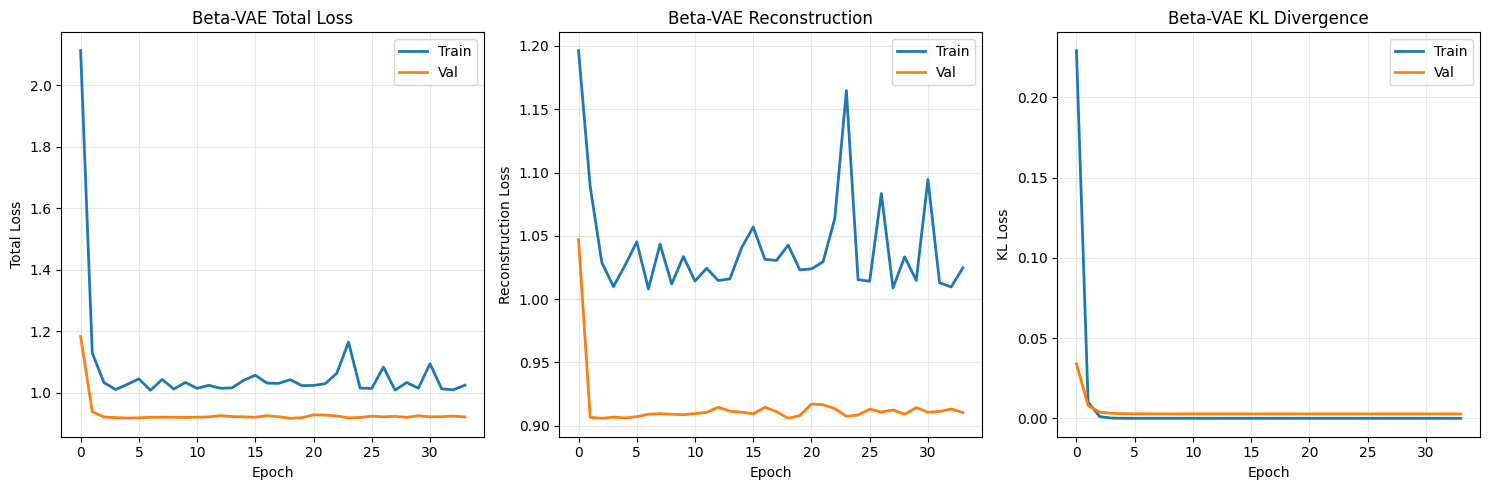

✓ Beta-VAE latent features: (683, 128)


In [ ]:
# ========================================
# CELL 7: Train Beta-VAE
# ========================================
print("\n" + "="*60)
print("TRAINING BETA-VAE")
print("="*60)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

lr_schedule = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=7,
    min_lr=1e-6
)

history_beta = beta_vae.fit(
    spec_flat_normalized,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping, lr_schedule],
    verbose=1
)

print(f"\n✓ Beta-VAE training complete (epochs: {len(history_beta.history['loss'])})")

# Plot training
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot(history_beta.history['loss'], label='Train', linewidth=2)
plt.plot(history_beta.history['val_loss'], label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Total Loss')
plt.legend()
plt.title('Beta-VAE Total Loss')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(history_beta.history['recon_loss'], label='Train', linewidth=2)
plt.plot(history_beta.history['val_recon_loss'], label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss')
plt.legend()
plt.title('Beta-VAE Reconstruction')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(history_beta.history['kl_loss'], label='Train', linewidth=2)
plt.plot(history_beta.history['val_kl_loss'], label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('KL Loss')
plt.legend()
plt.title('Beta-VAE KL Divergence')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(base_path + 'results/visualizations/beta_vae_training.png', dpi=300, bbox_inches='tight')
plt.show()

# Extract latent features
z_mean_beta_features, _, _ = beta_encoder.predict(spec_flat_normalized, verbose=0)
print(f"✓ Beta-VAE latent features: {z_mean_beta_features.shape}")



TRAINING CVAE
Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 275ms/step - kl_loss: 0.4063 - loss: 1.6008 - recon_loss: 1.1946 - val_kl_loss: 0.0432 - val_loss: 0.8480 - val_recon_loss: 0.8048 - learning_rate: 1.0000e-04
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 232ms/step - kl_loss: 0.0447 - loss: 1.0817 - recon_loss: 1.0370 - val_kl_loss: 0.0131 - val_loss: 0.7465 - val_recon_loss: 0.7334 - learning_rate: 1.0000e-04
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 272ms/step - kl_loss: 0.0050 - loss: 0.9766 - recon_loss: 0.9716 - val_kl_loss: 0.0069 - val_loss: 0.7445 - val_recon_loss: 0.7376 - learning_rate: 1.0000e-04
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 233ms/step - kl_loss: 0.0021 - loss: 0.9744 - recon_loss: 0.9722 - val_kl_loss: 0.0054 - val_loss: 0.7445 - val_recon_loss: 0.7391 - learning_rate: 1.0000e-04
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 235ms/step - kl_loss: 0.0020 - loss: 0.9736 - recon_loss: 0.9716 - val_kl_loss: 0.0046 - val_loss: 0.7423 - val_recon_loss: 0.7377 - learni

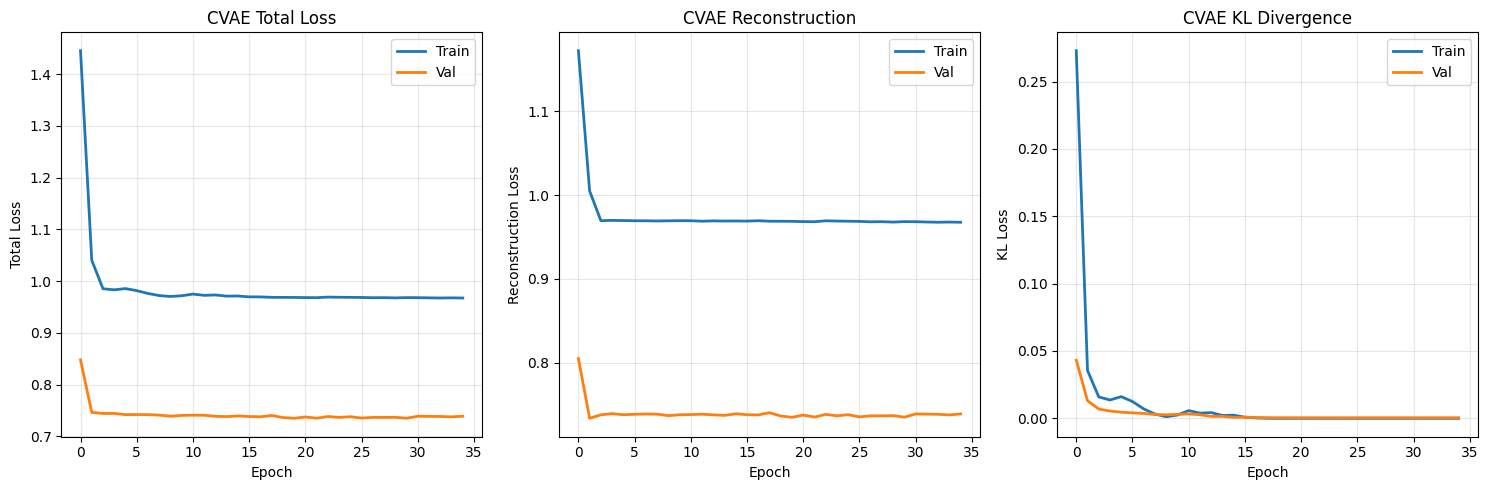

✓ CVAE latent features: (683, 128)


In [ ]:
# ========================================
# CELL 8: Train CVAE (if labels available)
# ========================================
if cvae:
    print("\n" + "="*60)
    print("TRAINING CVAE")
    print("="*60)

    early_stopping_cvae = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True
    )

    lr_schedule_cvae = keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=7,
        min_lr=1e-6
    )

    # Manual split for training and validation since validation_split is not supported for tf.data.Dataset
    from sklearn.model_selection import train_test_split

    # Split data into training and validation sets
    (train_spec, val_spec, train_labels, val_labels) = train_test_split(
        spec_flat_normalized, labels_onehot, test_size=0.2, random_state=42
    )

    # Create tf.data.Dataset for training
    train_dataset = tf.data.Dataset.from_tensor_slices(
        (train_spec, train_labels)
    ).batch(32).prefetch(tf.data.AUTOTUNE)

    # Create tf.data.Dataset for validation
    val_dataset = tf.data.Dataset.from_tensor_slices(
        (val_spec, val_labels)
    ).batch(32).prefetch(tf.data.AUTOTUNE)

    cvae.run_eagerly = True

    history_cvae = cvae.fit(
        train_dataset,
        epochs=100,
        validation_data=val_dataset, # Use validation_data for tf.data.Dataset
        callbacks=[early_stopping_cvae, lr_schedule_cvae],
        verbose=1
    )

    print(f"\n✓ CVAE training complete (epochs: {len(history_cvae.history['loss'])})")

    # Plot training
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.plot(history_cvae.history['loss'], label='Train', linewidth=2)
    plt.plot(history_cvae.history['val_loss'], label='Val', linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('Total Loss')
    plt.legend()
    plt.title('CVAE Total Loss')
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 3, 2)
    plt.plot(history_cvae.history['recon_loss'], label='Train', linewidth=2)
    plt.plot(history_cvae.history['val_recon_loss'], label='Val', linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('Reconstruction Loss')
    plt.legend()
    plt.title('CVAE Reconstruction')
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 3, 3)
    plt.plot(history_cvae.history['kl_loss'], label='Train', linewidth=2)
    plt.plot(history_cvae.history['val_kl_loss'], label='Val', linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('KL Loss')
    plt.legend()
    plt.title('CVAE KL Divergence')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(base_path + 'results/visualizations/cvae_training.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Extract latent features
    z_mean_cvae_features, _, _ = cvae_encoder.predict([spec_flat_normalized, labels_onehot], verbose=0)
    print(f"✓ CVAE latent features: {z_mean_cvae_features.shape}")
else:
    z_mean_cvae_features = None
    print("\n⚠️ Skipping CVAE training (no labels)")


TRAINING MULTI-MODAL VAE
Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 483ms/step - audio_recon_loss: 1.2014 - kl_loss: 0.1258 - loss: 2.5739 - lyrics_recon_loss: 1.2467 - val_audio_recon_loss: 0.8510 - val_kl_loss: 0.0235 - val_loss: 2.1702 - val_lyrics_recon_loss: 1.2958 - learning_rate: 1.0000e-04
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - audio_recon_loss: 1.1311 - kl_loss: 0.0178 - loss: 2.3468 - lyrics_recon_loss: 1.1979 - val_audio_recon_loss: 0.7646 - val_kl_loss: 0.0143 - val_loss: 2.0275 - val_lyrics_recon_loss: 1.2486 - learning_rate: 1.0000e-04
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - audio_recon_loss: 1.0089 - kl_loss: 0.0219 - loss: 2.1773 - lyrics_recon_loss: 1.1464 - val_audio_recon_loss: 0.7285 - val_kl_loss: 0.0145 - val_loss: 1.9407 - val_lyrics_recon_loss: 1.1976 - learning_rate: 1.0000e-04
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - audio_recon_loss: 0.9651 - kl_loss: 0.0207 - loss: 2.0753 - lyrics_recon_loss: 1.0895 - val_audio_reco

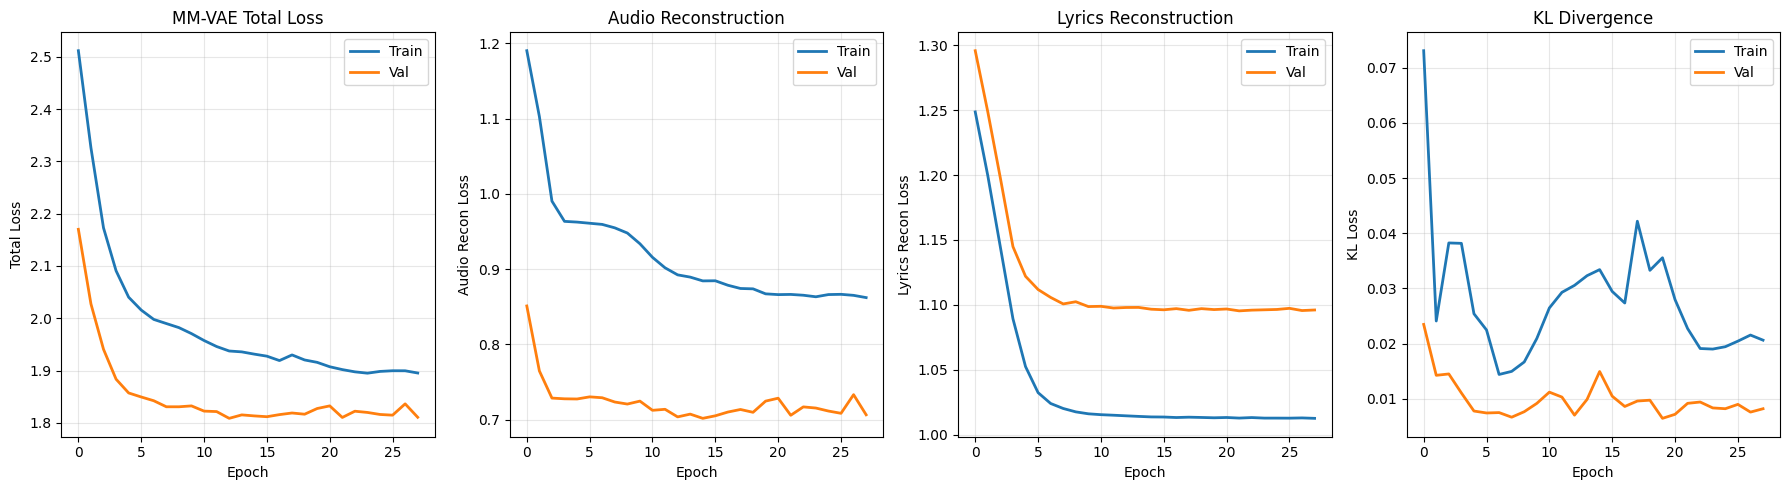

✓ Multi-Modal VAE latent features: (683, 128)


In [ ]:
# ========================================
# CELL 9: Train Multi-Modal VAE
# ========================================
print("\n" + "="*60)
print("TRAINING MULTI-MODAL VAE")
print("="*60)

early_stopping_mm = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

lr_schedule_mm = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=7,
    min_lr=1e-6
)

# Manual split for training and validation since validation_split is not supported for tf.data.Dataset
from sklearn.model_selection import train_test_split

# Combine the two modalities into a single array for splitting
X_combined = np.hstack((spec_flat_normalized, lyrics_normalized))

indices = np.arange(len(spec_flat_normalized))
train_indices, val_indices = train_test_split(indices, test_size=0.2, random_state=42)

train_spec = spec_flat_normalized[train_indices]
train_lyrics = lyrics_normalized[train_indices]
val_spec = spec_flat_normalized[val_indices]
val_lyrics = lyrics_normalized[val_indices]

train_mm_dataset = tf.data.Dataset.from_tensor_slices(
    ((train_spec, train_lyrics), (train_spec, train_lyrics))
).batch(32).prefetch(tf.data.AUTOTUNE)

val_mm_dataset = tf.data.Dataset.from_tensor_slices(
    ((val_spec, val_lyrics), (val_spec, val_lyrics))
).batch(32).prefetch(tf.data.AUTOTUNE)

history_mm = mm_vae.fit(train_mm_dataset,
    epochs=100,
    validation_data=val_mm_dataset, # Use validation_data for tf.data.Dataset
    callbacks=[early_stopping_mm, lr_schedule_mm],
    verbose=1
)
print(f"\n✓ Multi-Modal VAE training complete (epochs: {len(history_mm.history['loss'])})")

# Plot training
plt.figure(figsize=(18, 5))
plt.subplot(1, 4, 1)
plt.plot(history_mm.history['loss'], label='Train', linewidth=2)
plt.plot(history_mm.history['val_loss'], label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Total Loss')
plt.legend()
plt.title('MM-VAE Total Loss')
plt.grid(True, alpha=0.3)

plt.subplot(1, 4, 2)
plt.plot(history_mm.history['audio_recon_loss'], label='Train', linewidth=2)
plt.plot(history_mm.history['val_audio_recon_loss'], label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Audio Recon Loss')
plt.legend()
plt.title('Audio Reconstruction')
plt.grid(True, alpha=0.3)

plt.subplot(1, 4, 3)
plt.plot(history_mm.history['lyrics_recon_loss'], label='Train', linewidth=2)
plt.plot(history_mm.history['val_lyrics_recon_loss'], label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Lyrics Recon Loss')
plt.legend()
plt.title('Lyrics Reconstruction')
plt.grid(True, alpha=0.3)

plt.subplot(1, 4, 4)
plt.plot(history_mm.history['kl_loss'], label='Train', linewidth=2)
plt.plot(history_mm.history['val_kl_loss'], label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('KL Loss')
plt.legend()
plt.title('KL Divergence')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(base_path + 'results/visualizations/mm_vae_training.png', dpi=300, bbox_inches='tight')
plt.show()

# Extract latent features
z_mean_mm_features, _, _ = mm_encoder.predict([spec_flat_normalized, lyrics_normalized], verbose=0)
print(f"✓ Multi-Modal VAE latent features: {z_mean_mm_features.shape}")

In [ ]:
# ========================================
# CELL 10: Comprehensive Clustering
# ========================================
print("\n" + "="*60)
print("COMPREHENSIVE CLUSTERING EVALUATION")
print("="*60)

def evaluate_clustering(features, clusters, method_name, true_labels=None):
    """Comprehensive clustering evaluation"""

    valid_cluster_ids = np.unique(clusters[clusters >= 0])
    if len(valid_cluster_ids) < 2:
        print(f"\n{method_name}: Less than 2 valid clusters found (unique_ids={len(valid_cluster_ids)}) - skipping metrics")
        return None

    # Basic metrics - these handle -1 (noise) correctly by ignoring them
    silhouette = silhouette_score(features, clusters)
    davies_bouldin = davies_bouldin_score(features, clusters)
    calinski = calinski_harabasz_score(features, clusters)

    # Cluster balance - filter out noise points for bincount
    valid_clusters = clusters[clusters >= 0]
    if len(valid_clusters) == 0: # All points are noise
        print(f"\n{method_name}: All points assigned as noise by DBSCAN - skipping balance metrics")
        return None

    cluster_sizes = np.bincount(valid_clusters) # Only count positive cluster IDs
    balance_ratio = cluster_sizes.min() / cluster_sizes.max()

    # Label-based metrics (if available)
    if true_labels is not None:
        # NMI and ARI handle -1 (noise) correctly by ignoring them
        nmi = normalized_mutual_info_score(true_labels, clusters)
        ari = adjusted_rand_score(true_labels, clusters)

        # Cluster purity: calculated only for non-noise points
        total_correctly_classified = 0
        non_noise_indices = (clusters != -1)
        if non_noise_indices.sum() > 0:
            for cluster_id in np.unique(clusters[non_noise_indices]):
                # Find true labels for points in this cluster (excluding noise)
                cluster_true_labels = true_labels[clusters == cluster_id]
                if len(cluster_true_labels) > 0:
                    # Find the most frequent true label in this cluster
                    most_common_label_count = np.bincount(cluster_true_labels).max()
                    total_correctly_classified += most_common_label_count
            purity = total_correctly_classified / non_noise_indices.sum()
        else:
            purity = 0.0
    else:
        nmi = None
        ari = None
        purity = None

    results = {
        'method': method_name,
        'silhouette': silhouette,
        'davies_bouldin': davies_bouldin,
        'calinski': calinski,
        'balance_ratio': balance_ratio,
        'cluster_sizes': cluster_sizes,
        'nmi': nmi,
        'ari': ari,
        'purity': purity
    }

    return results

# Prepare baseline (PCA + Autoencoder)
print("\n1. Preparing Baselines...")

# PCA
pca = PCA(n_components=128)
pca_features = pca.fit_transform(spec_flat_normalized)
print(f"   PCA features: {pca_features.shape}, Explained variance: {pca.explained_variance_ratio_.sum():.4f}")

# Simple Autoencoder
ae_input = keras.Input(shape=(spec_flat_normalized.shape[1],))
ae_encoded = layers.Dense(1024, activation='relu')(ae_input)
ae_encoded = layers.Dense(512, activation='relu')(ae_encoded)
ae_encoded = layers.Dense(128, activation='relu')(ae_encoded)

ae_decoded = layers.Dense(512, activation='relu')(ae_encoded)
ae_decoded = layers.Dense(1024, activation='relu')(ae_decoded)
ae_decoded = layers.Dense(spec_flat_normalized.shape[1], activation='sigmoid')(ae_decoded)

autoencoder = Model(ae_input, ae_decoded)
encoder_ae = Model(ae_input, ae_encoded)

autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.fit(spec_flat_normalized, spec_flat_normalized,
                epochs=50, batch_size=32, validation_split=0.2, verbose=0)

ae_features = encoder_ae.predict(spec_flat_normalized, verbose=0)
print(f"   Autoencoder features: {ae_features.shape}")

# Direct spectral features (flattened spectrograms with PCA for dimensionality)
spectral_pca = PCA(n_components=128)
spectral_features = spectral_pca.fit_transform(spec_flat_normalized)
print(f"   Spectral features: {spectral_features.shape}")

# Collect all feature sets
feature_sets = {
    'Beta-VAE': z_mean_beta_features,
    'Multi-Modal VAE': z_mean_mm_features,
    'PCA': pca_features,
    'Autoencoder': ae_features,
    'Spectral': spectral_features
}

if z_mean_cvae_features is not None:
    feature_sets['CVAE'] = z_mean_cvae_features

# Clustering algorithms
print("\n2. Testing Multiple Clustering Algorithms...")

clustering_algorithms = {
    'K-Means': lambda k: KMeans(n_clusters=k, random_state=42, n_init=10),
    'Agglomerative': lambda k: AgglomerativeClustering(n_clusters=k, linkage='ward'),
    'DBSCAN': lambda k: DBSCAN(eps=0.5, min_samples=5)
}

# Determine optimal k
optimal_k = 5  # Default
if has_labels:
    optimal_k = n_classes
    print(f"   Using k={optimal_k} (from labels)")
else:
    # Try to find optimal k using elbow method
    print("   Finding optimal k using silhouette scores...")
    sil_scores = []
    k_range = range(3, 11)
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        clusters = kmeans.fit_predict(z_mean_mm_features)
        # Ensure there are at least 2 unique labels (excluding -1) for silhouette score
        if len(np.unique(clusters[clusters >= 0])) > 1:
            sil = silhouette_score(z_mean_mm_features, clusters)
            sil_scores.append(sil)
        else:
            sil_scores.append(-1) # Assign a low score if not enough clusters

    # Check if any valid silhouette scores were found
    if max(sil_scores) > -1:
        optimal_k = list(k_range)[np.argmax(sil_scores)]
        print(f"   Optimal k={optimal_k} (silhouette: {max(sil_scores):.4f})")
    else:
        print("   Could not determine optimal k using silhouette (not enough clusters found).")
        optimal_k = 3 # Fallback to a default k

# Perform clustering and evaluation
all_results = []

for feat_name, features in feature_sets.items():
    print(f"\n{'='*60}")
    print(f"Feature Set: {feat_name}")
    print(f"{'='*60}")

    for algo_name, algo_func in clustering_algorithms.items():
        print(f"\n  Algorithm: {algo_name}")

        # Perform clustering
        if algo_name == 'DBSCAN':
            algo = algo_func(None)
            clusters = algo.fit_predict(features)
        else:
            algo = algo_func(optimal_k)
            clusters = algo.fit_predict(features)

        # Evaluate
        true_labels_eval = labels_encoded if has_labels else None
        results = evaluate_clustering(features, clusters,
                                      f"{feat_name} + {algo_name}",
                                      true_labels_eval)

        if results:
            all_results.append(results)

            print(f"    Silhouette: {results['silhouette']:.4f}")
            print(f"    Davies-Bouldin: {results['davies_bouldin']:.4f}")
            print(f"    Calinski-Harabasz: {results['calinski']:.2f}")
            print(f"    Balance Ratio: {results['balance_ratio']:.3f}")
            # Print cluster sizes as string since it's an array
            print(f"    Cluster Sizes: {results['cluster_sizes'].tolist()}")

            if results['nmi'] is not None:
                print(f"    NMI: {results['nmi']:.4f}")
                print(f"    ARI: {results['ari']:.4f}")
                print(f"    Purity: {results['purity']:.4f}")


COMPREHENSIVE CLUSTERING EVALUATION

1. Preparing Baselines...
   PCA features: (683, 128), Explained variance: 0.7422
   Autoencoder features: (683, 128)
   Spectral features: (683, 128)

2. Testing Multiple Clustering Algorithms...
   Using k=5 (from labels)

Feature Set: Beta-VAE

  Algorithm: K-Means
    Silhouette: 0.8940
    Davies-Bouldin: 0.0529
    Calinski-Harabasz: 42.82
    Balance Ratio: 0.001
    Cluster Sizes: [679, 1, 1, 1, 1]
    NMI: 0.0099
    ARI: -0.0012
    Purity: 0.2665

  Algorithm: Agglomerative
    Silhouette: 0.9067
    Davies-Bouldin: 1.5528
    Calinski-Harabasz: 51.90
    Balance Ratio: 0.001
    Cluster Sizes: [12, 667, 1, 2, 1]
    NMI: 0.0384
    ARI: -0.0033
    Purity: 0.2840

  Algorithm: DBSCAN

Beta-VAE + DBSCAN: Less than 2 valid clusters found (unique_ids=1) - skipping metrics

Feature Set: Multi-Modal VAE

  Algorithm: K-Means
    Silhouette: 0.3147
    Davies-Bouldin: 1.0253
    Calinski-Harabasz: 898.81
    Balance Ratio: 0.219
    Cluster S

In [ ]:
# ========================================
# CELL 11: Results Summary
# ========================================
print("\n" + "="*60)
print("COMPREHENSIVE RESULTS SUMMARY")
print("="*60)

# Create results DataFrame
results_df = pd.DataFrame(all_results)

# Display full results
print("\n" + results_df.to_string(index=False))

# Save results
results_df.to_csv(base_path + 'results/metrics/hard_task_comprehensive_metrics.csv', index=False)
print(f"\n✓ Results saved to: {base_path}results/metrics/hard_task_comprehensive_metrics.csv")

# Find best methods
print("\n" + "="*60)
print("BEST PERFORMING METHODS")
print("="*60)

# Best by Silhouette
best_sil = results_df.loc[results_df['silhouette'].idxmax()]
print(f"\nBest Silhouette Score:")
print(f"  Method: {best_sil['method']}")
print(f"  Score: {best_sil['silhouette']:.4f}")
print(f"  Balance: {best_sil['balance_ratio']:.3f}")

# Best by Davies-Bouldin (lower is better)
best_db = results_df.loc[results_df['davies_bouldin'].idxmin()]
print(f"\nBest Davies-Bouldin Index:")
print(f"  Method: {best_db['method']}")
print(f"  Score: {best_db['davies_bouldin']:.4f}")
print(f"  Balance: {best_db['balance_ratio']:.3f}")

if has_labels:
    # Best by NMI
    best_nmi = results_df.loc[results_df['nmi'].idxmax()]
    print(f"\nBest NMI:")
    print(f"  Method: {best_nmi['method']}")
    print(f"  NMI: {best_nmi['nmi']:.4f}")
    print(f"  ARI: {best_nmi['ari']:.4f}")
    print(f"  Purity: {best_nmi['purity']:.4f}")



COMPREHENSIVE RESULTS SUMMARY

                         method  silhouette  davies_bouldin   calinski  balance_ratio            cluster_sizes      nmi       ari   purity
             Beta-VAE + K-Means    0.894042        0.052871  42.816078       0.001473        [679, 1, 1, 1, 1] 0.009925 -0.001162 0.266471
       Beta-VAE + Agglomerative    0.906725        1.552756  51.904858       0.001499       [12, 667, 1, 2, 1] 0.038394 -0.003321 0.284041
      Multi-Modal VAE + K-Means    0.314719        1.025310 898.814941       0.219101 [175, 144, 39, 178, 147] 0.039111  0.033390 0.349927
Multi-Modal VAE + Agglomerative    0.285981        0.998785 826.800781       0.125561 [223, 171, 131, 28, 130] 0.034983  0.033078 0.346999
                  PCA + K-Means    0.082906        2.360243 118.578705       0.331878 [136, 123, 119, 229, 76] 0.088562  0.066735 0.387994
            PCA + Agglomerative    0.029853        2.635545 106.013451       0.223938 [259, 132, 120, 58, 114] 0.034695  0.025491 0.35


GENERATING VISUALIZATIONS


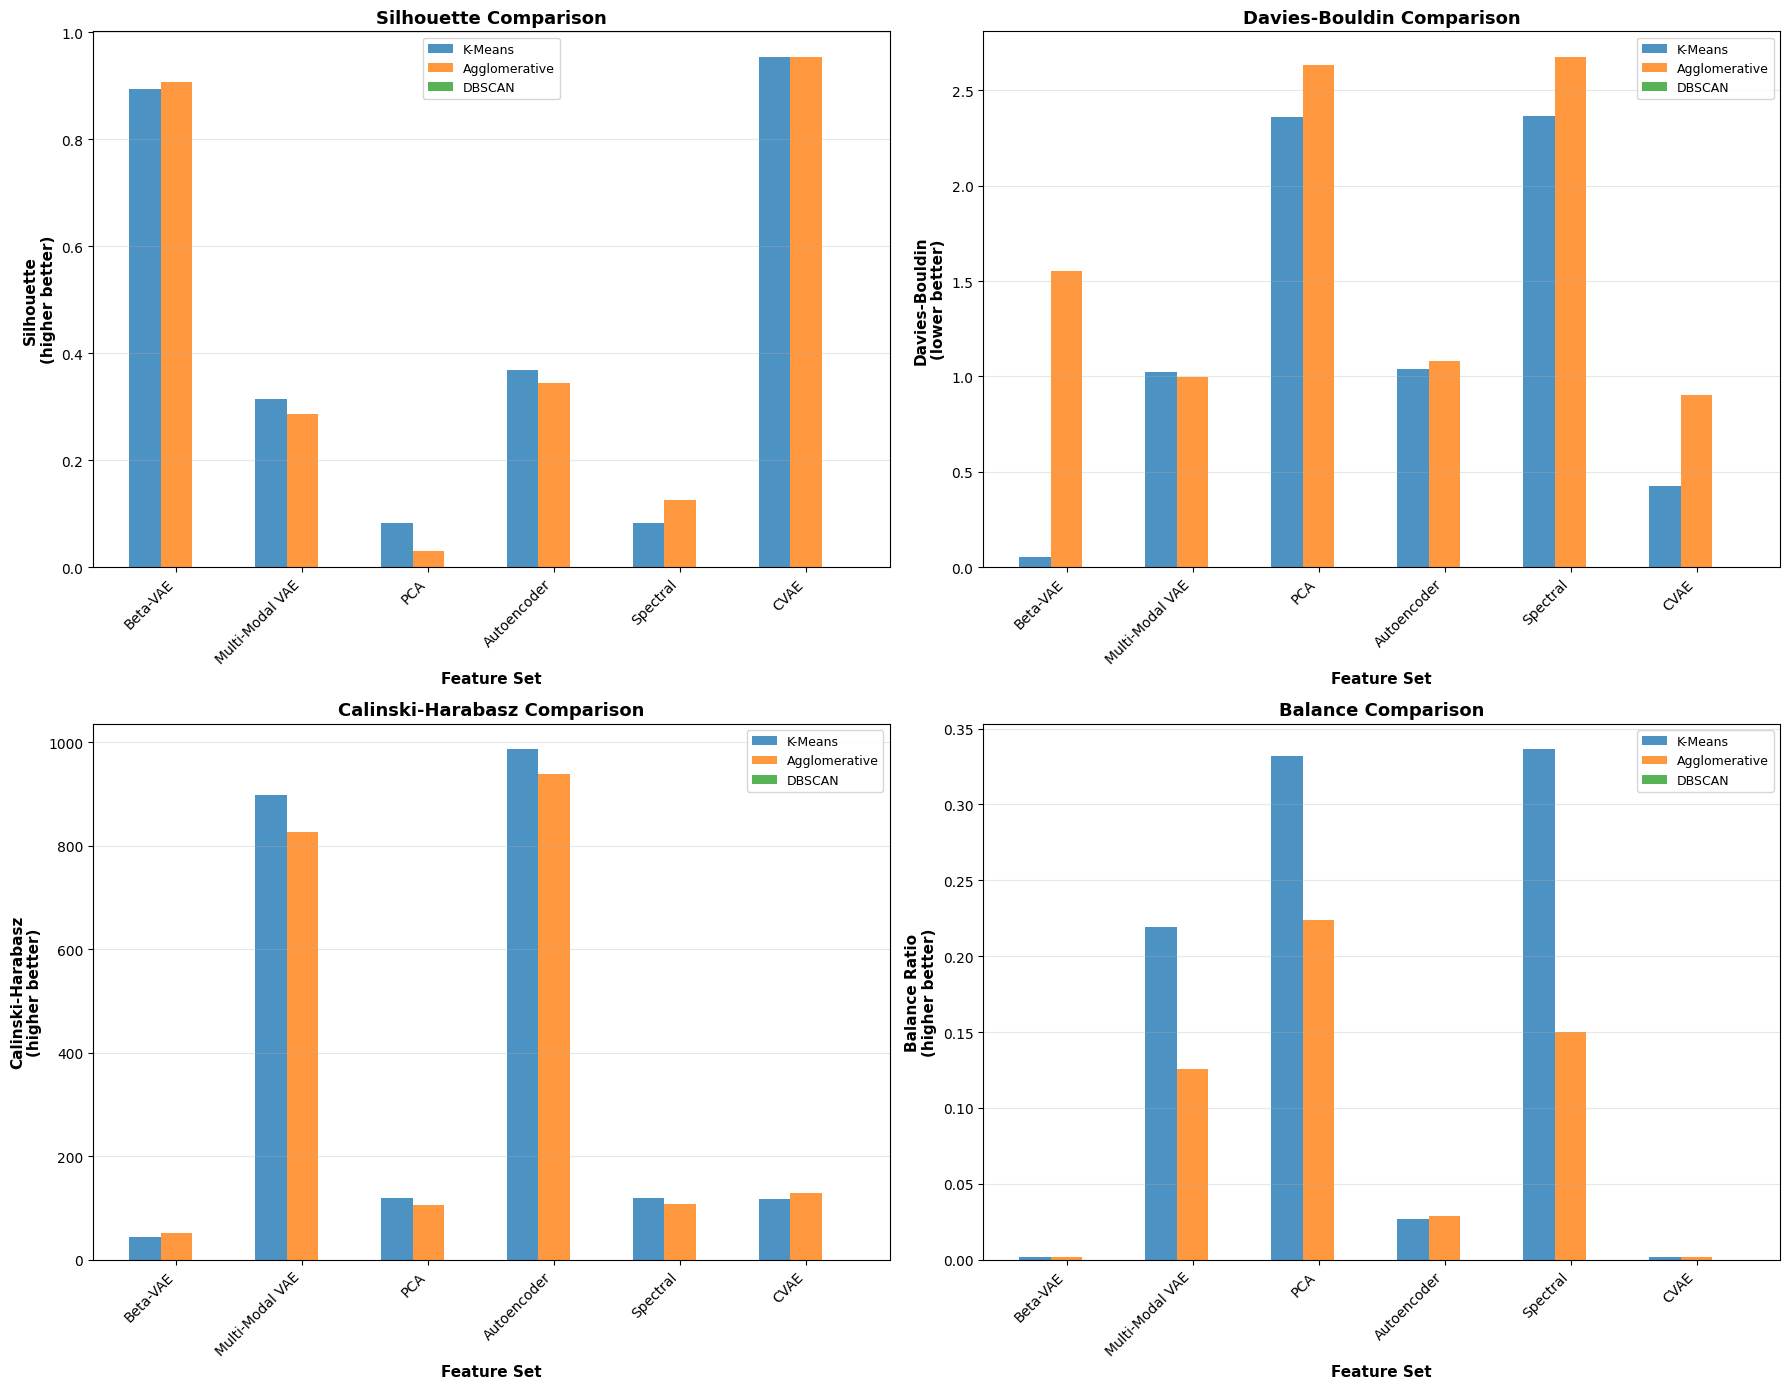

In [ ]:
# ========================================
# CELL 12: Visualization - Metrics Comparison
# ========================================
print("\n" + "="*60)
print("GENERATING VISUALIZATIONS")
print("="*60)

# Metrics comparison heatmap
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Prepare data for plotting
plot_methods = results_df['method'].values
metrics_to_plot = ['silhouette', 'davies_bouldin', 'calinski', 'balance_ratio']
metric_labels = ['Silhouette\n(higher better)', 'Davies-Bouldin\n(lower better)',
                 'Calinski-Harabasz\n(higher better)', 'Balance Ratio\n(higher better)']

for idx, (metric, label) in enumerate(zip(metrics_to_plot, metric_labels)):
    ax = axes[idx // 2, idx % 2]

    # Group by feature set
    feature_sets_plot = []
    for method in plot_methods:
        feature_sets_plot.append(method.split(' + ')[0])

    unique_features = list(dict.fromkeys(feature_sets_plot))

    # Create grouped bar chart
    x = np.arange(len(unique_features))
    width = 0.25

    algo_names = list(clustering_algorithms.keys())
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

    for i, algo in enumerate(algo_names):
        values = []
        for feat in unique_features:
            matching = results_df[results_df['method'] == f"{feat} + {algo}"]
            if len(matching) > 0:
                values.append(matching[metric].values[0])
            else:
                values.append(0)

        ax.bar(x + i*width, values, width, label=algo, color=colors[i], alpha=0.8)

    ax.set_xlabel('Feature Set', fontsize=11, fontweight='bold')
    ax.set_ylabel(label, fontsize=11, fontweight='bold')
    ax.set_title(f'{label.split()[0]} Comparison', fontsize=13, fontweight='bold')
    ax.set_xticks(x + width)
    ax.set_xticklabels(unique_features, rotation=45, ha='right')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(base_path + 'results/visualizations/metrics_comparison_hard.png', dpi=300, bbox_inches='tight')
plt.show()


Generating latent space visualizations...


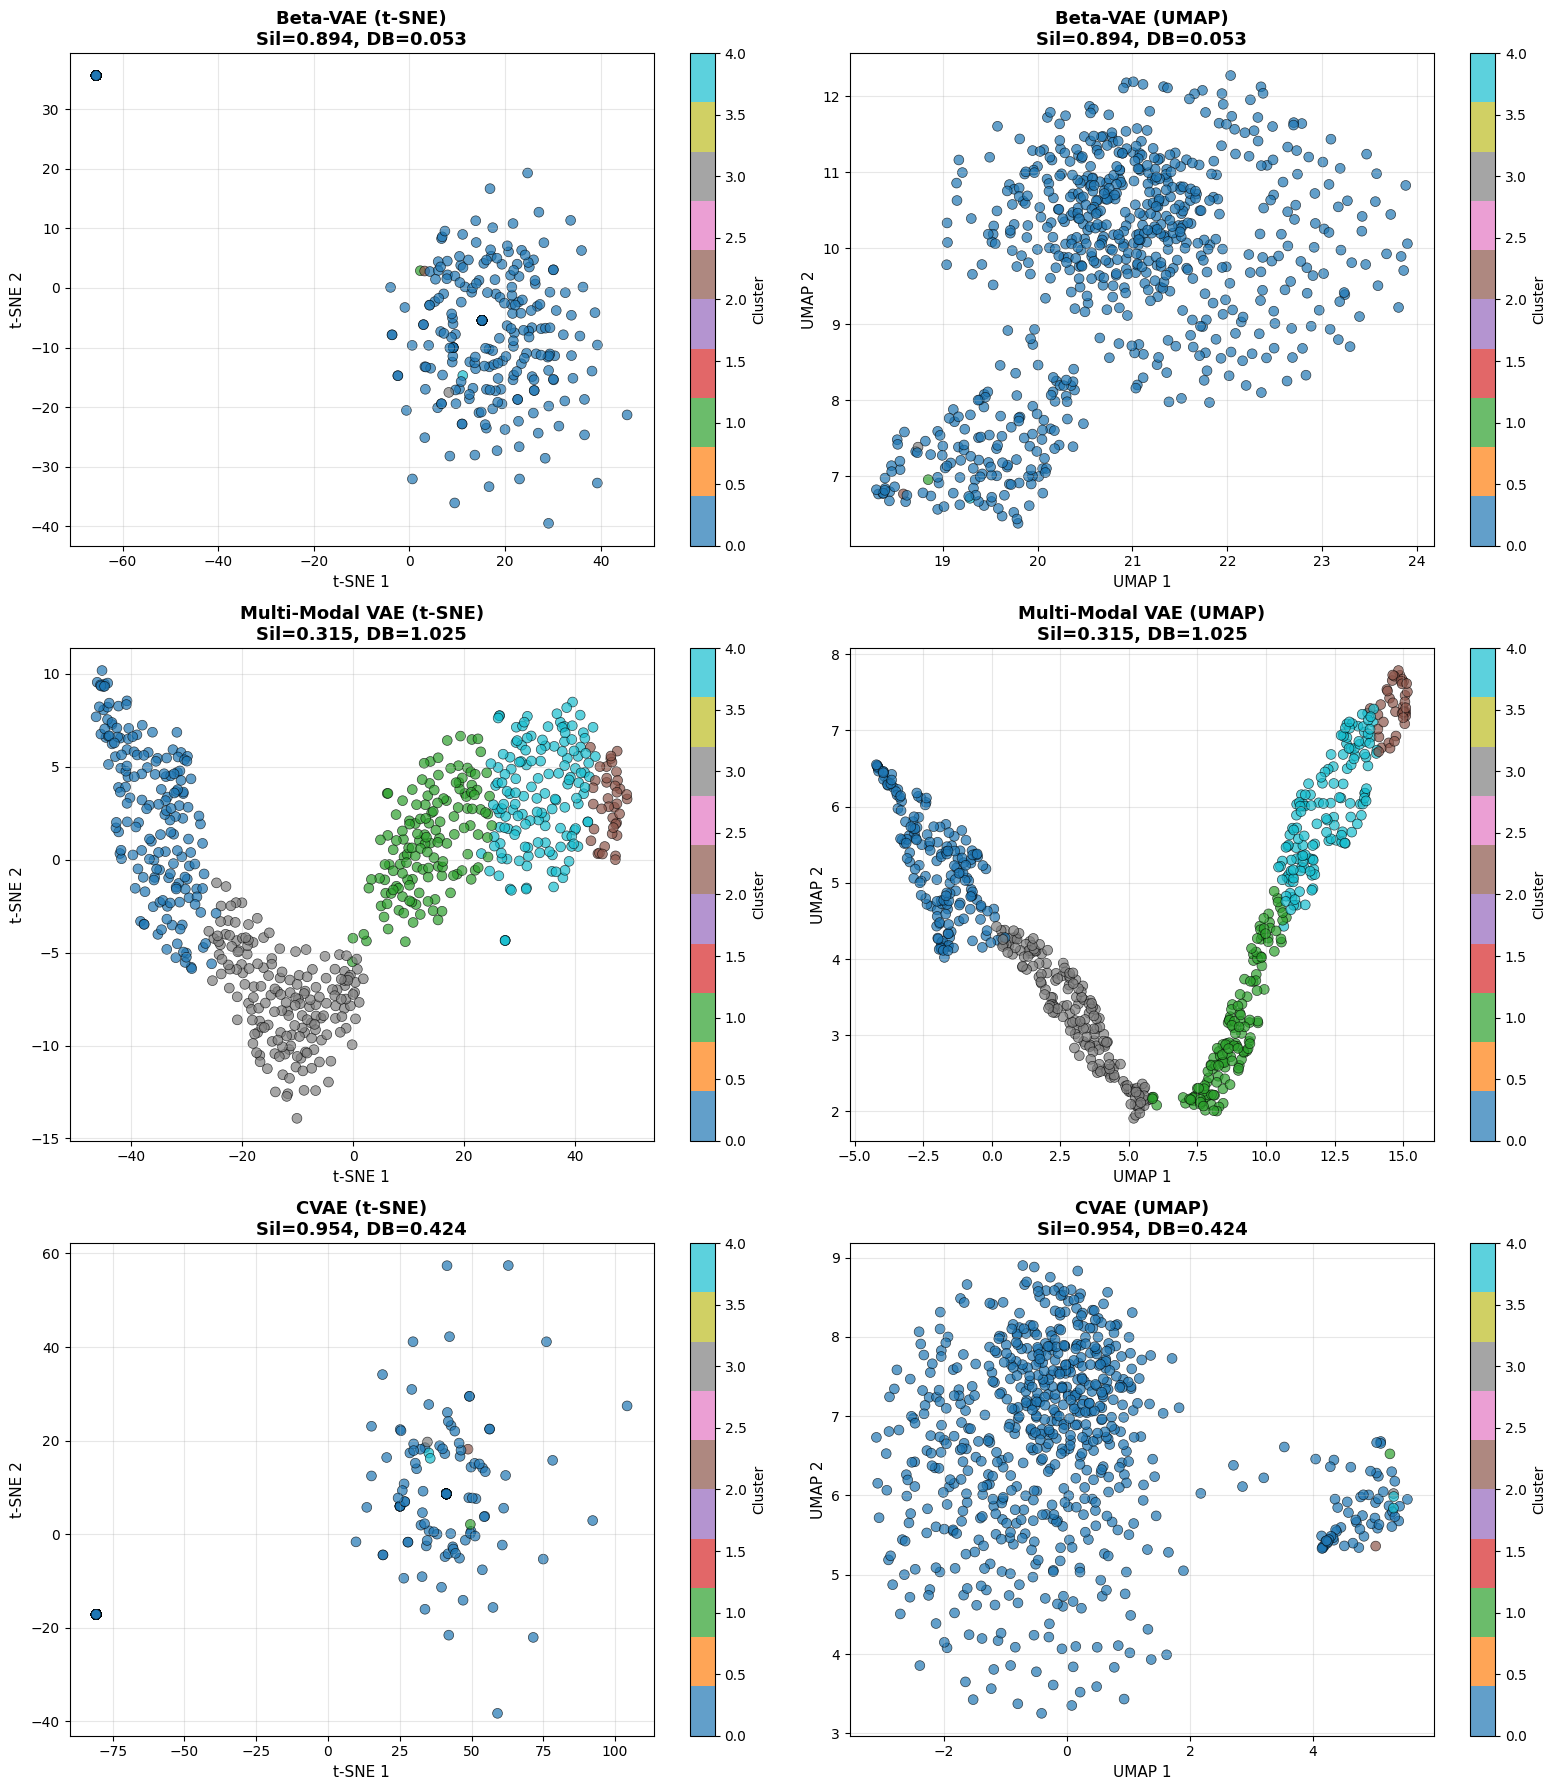

In [ ]:
# ========================================
# CELL 13: Latent Space Visualizations
# ========================================
print("\nGenerating latent space visualizations...")

# Select best method from each VAE type for visualization
vae_methods = {
    'Beta-VAE': z_mean_beta_features,
    'Multi-Modal VAE': z_mean_mm_features
}

if z_mean_cvae_features is not None:
    vae_methods['CVAE'] = z_mean_cvae_features

# Get clusters for each
vae_clusters_dict = {}
for name, features in vae_methods.items():
    kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    vae_clusters_dict[name] = kmeans.fit_predict(features)

# Create comprehensive visualization
fig, axes = plt.subplots(len(vae_methods), 2, figsize=(16, 6*len(vae_methods)))

if len(vae_methods) == 1:
    axes = axes.reshape(1, -1)

for idx, (name, features) in enumerate(vae_methods.items()):
    clusters = vae_clusters_dict[name]

    # Get metrics for title
    method_results = results_df[results_df['method'] == f"{name} + K-Means"]
    if len(method_results) > 0:
        sil = method_results['silhouette'].values[0]
        db = method_results['davies_bouldin'].values[0]
    else:
        sil, db = 0, 0

    # t-SNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(features)-1))
    tsne_features = tsne.fit_transform(features)

    scatter = axes[idx, 0].scatter(tsne_features[:, 0], tsne_features[:, 1],
                                   c=clusters, cmap='tab10', alpha=0.7, s=50,
                                   edgecolors='black', linewidth=0.5)
    axes[idx, 0].set_title(f'{name} (t-SNE)\nSil={sil:.3f}, DB={db:.3f}',
                          fontsize=13, fontweight='bold')
    axes[idx, 0].set_xlabel('t-SNE 1', fontsize=11)
    axes[idx, 0].set_ylabel('t-SNE 2', fontsize=11)
    plt.colorbar(scatter, ax=axes[idx, 0], label='Cluster')
    axes[idx, 0].grid(True, alpha=0.3)

    # UMAP
    reducer = umap.UMAP(random_state=42, n_neighbors=15, min_dist=0.1)
    umap_features = reducer.fit_transform(features)

    scatter = axes[idx, 1].scatter(umap_features[:, 0], umap_features[:, 1],
                                   c=clusters, cmap='tab10', alpha=0.7, s=50,
                                   edgecolors='black', linewidth=0.5)
    axes[idx, 1].set_title(f'{name} (UMAP)\nSil={sil:.3f}, DB={db:.3f}',
                          fontsize=13, fontweight='bold')
    axes[idx, 1].set_xlabel('UMAP 1', fontsize=11)
    axes[idx, 1].set_ylabel('UMAP 2', fontsize=11)
    plt.colorbar(scatter, ax=axes[idx, 1], label='Cluster')
    axes[idx, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(base_path + 'results/visualizations/latent_space_comparison_hard.png', dpi=300, bbox_inches='tight')
plt.show()



Generating cluster vs label distribution...


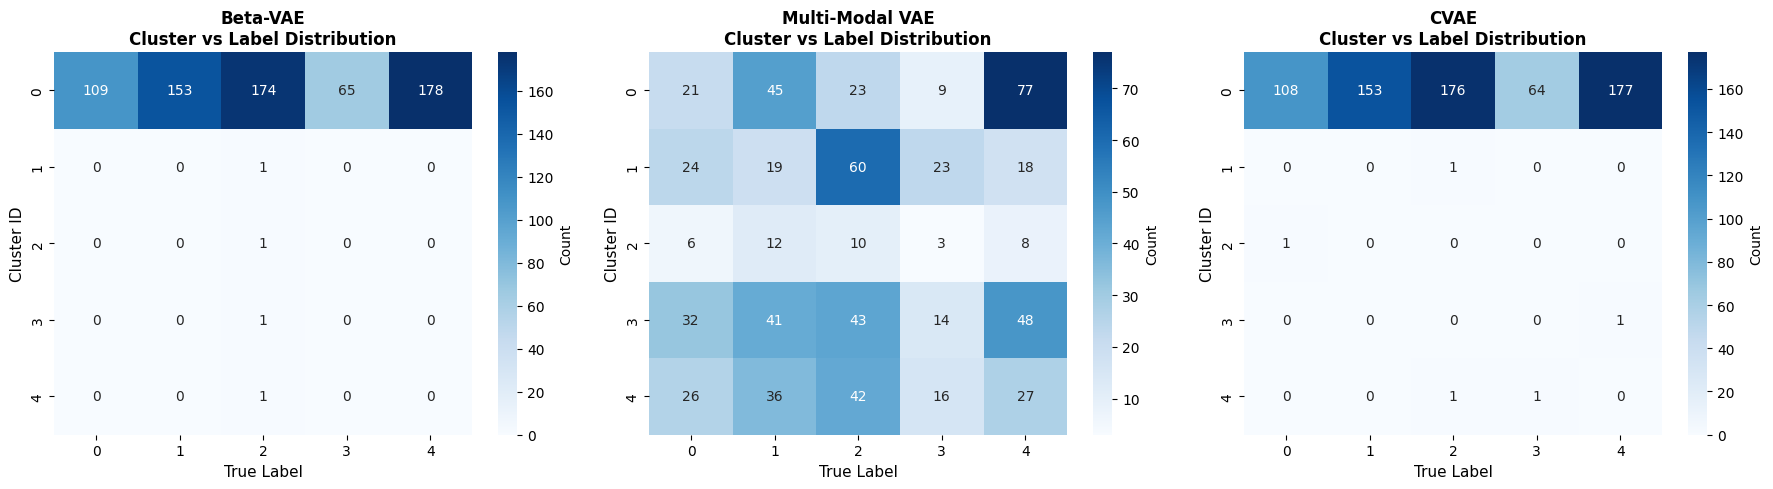

In [ ]:
# ========================================
# CELL 14: Cluster Distribution Over Labels (if available)
# ========================================
if has_labels:
    print("\nGenerating cluster vs label distribution...")

    fig, axes = plt.subplots(1, len(vae_methods), figsize=(6*len(vae_methods), 5))

    if len(vae_methods) == 1:
        axes = [axes]

    for idx, (name, features) in enumerate(vae_methods.items()):
        clusters = vae_clusters_dict[name]

        # Create confusion matrix
        confusion_mat = pd.crosstab(clusters, labels_encoded,
                                   rownames=['Cluster'], colnames=['True Label'])

        sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues',
                   ax=axes[idx], cbar_kws={'label': 'Count'})
        axes[idx].set_title(f'{name}\nCluster vs Label Distribution',
                           fontsize=12, fontweight='bold')
        axes[idx].set_xlabel('True Label', fontsize=11)
        axes[idx].set_ylabel('Cluster ID', fontsize=11)

    plt.tight_layout()
    plt.savefig(base_path + 'results/visualizations/cluster_label_distribution_hard.png', dpi=300, bbox_inches='tight')
    plt.show()



Generating reconstruction quality plots...


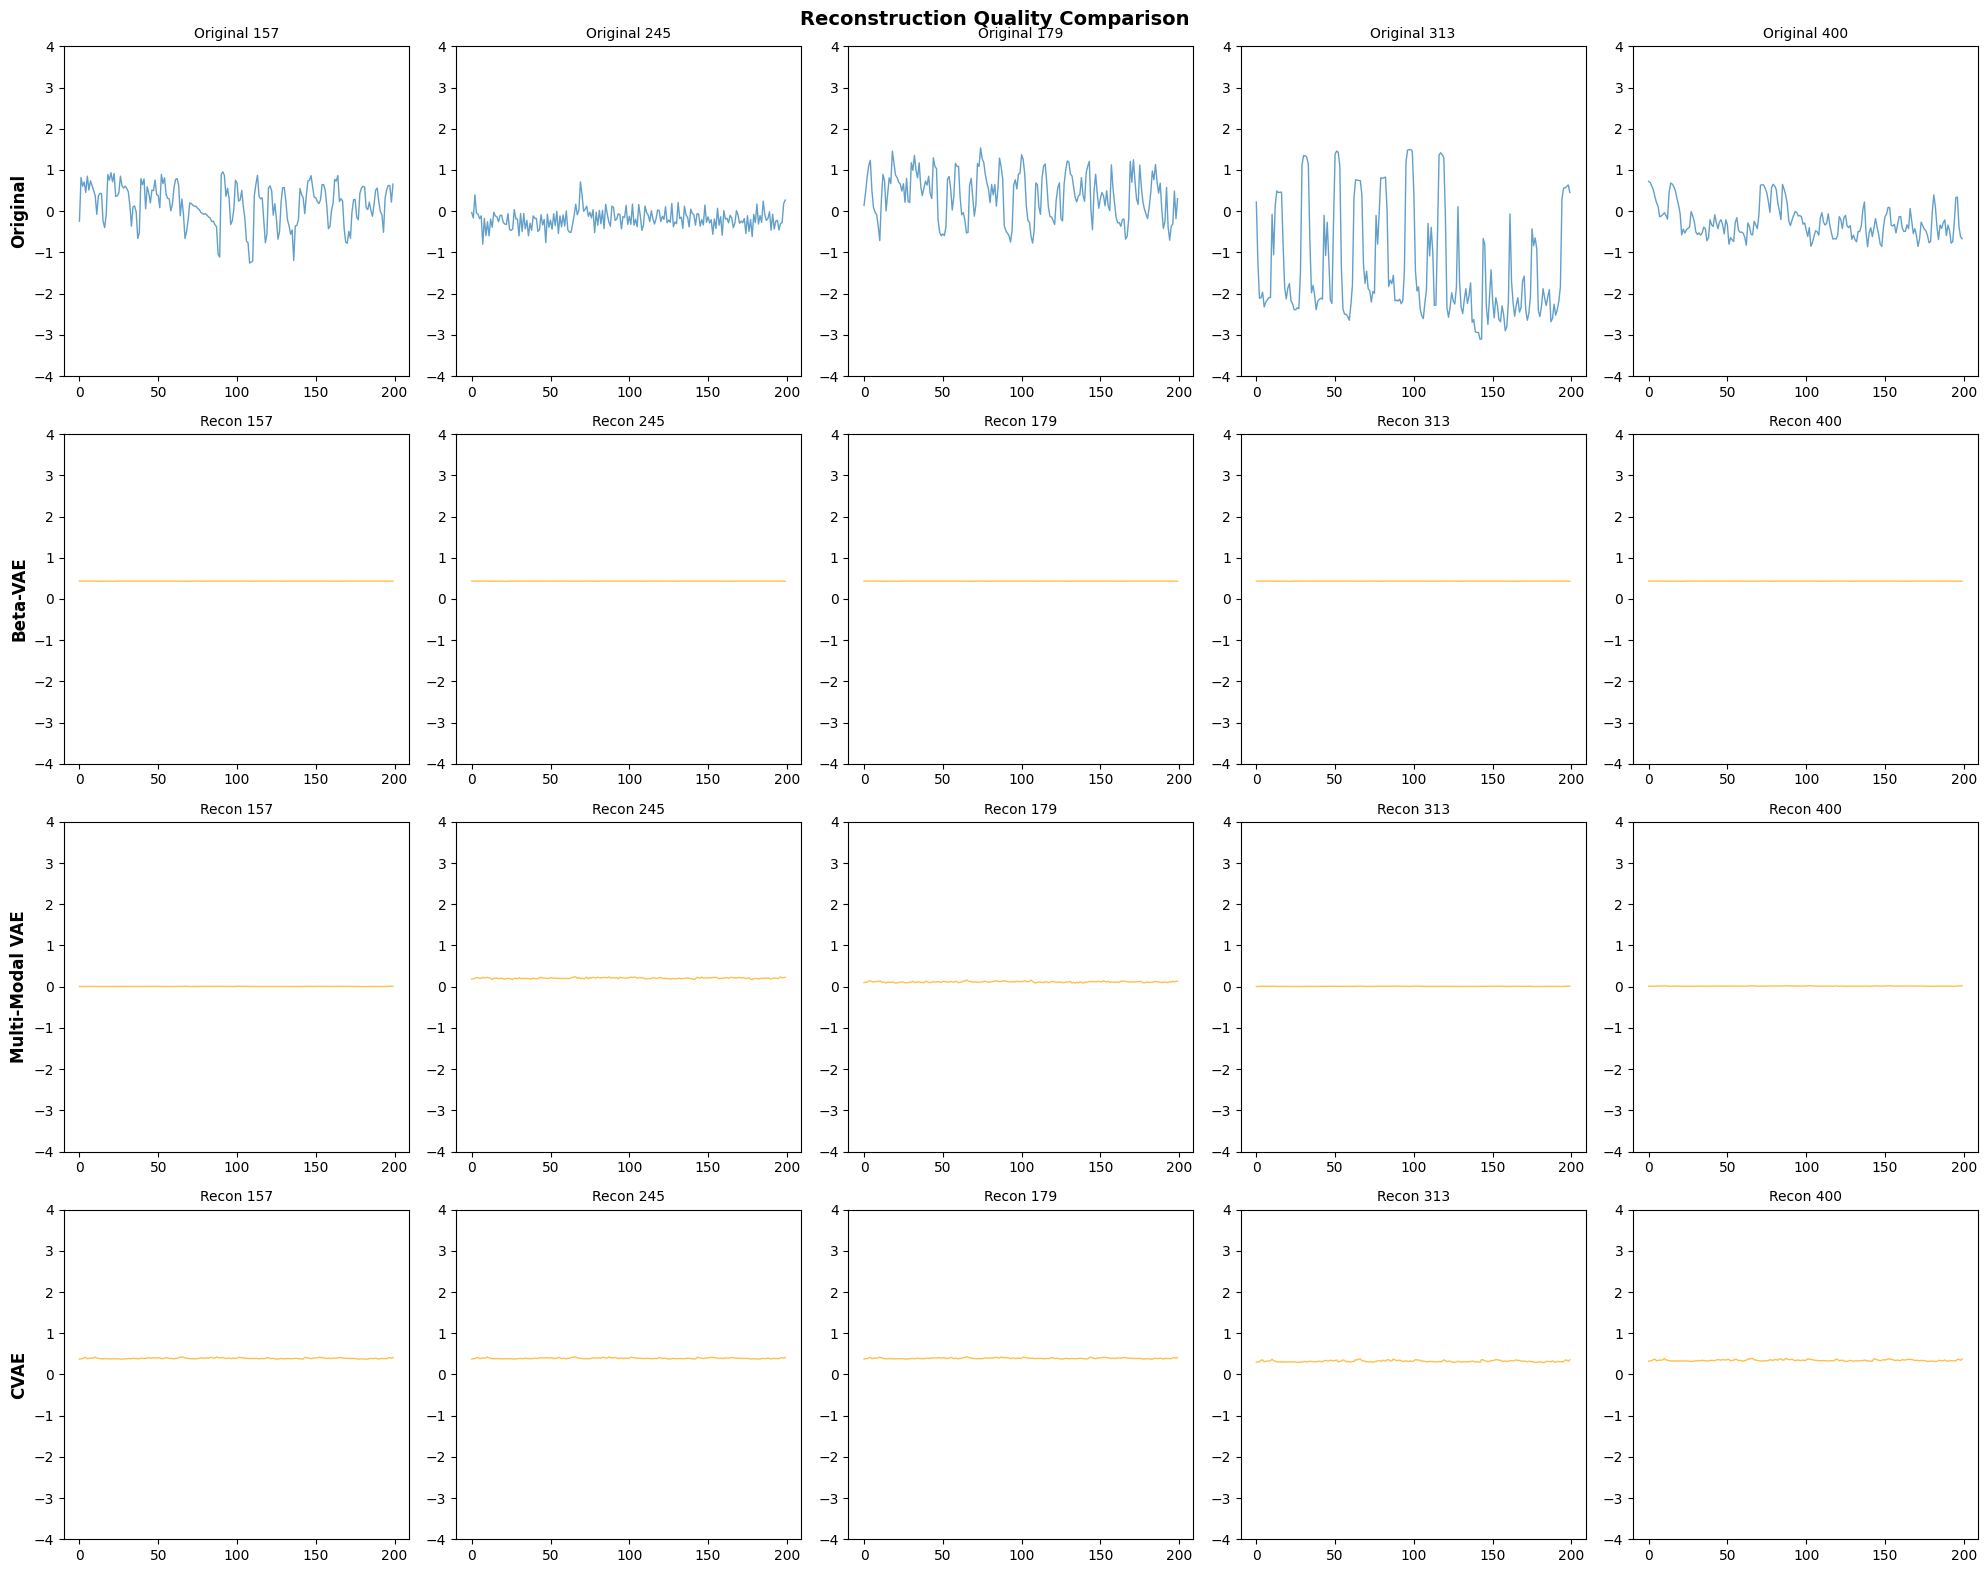

In [ ]:
# ========================================
# CELL 15: Reconstruction Quality
# ========================================
print("\nGenerating reconstruction quality plots...")

n_samples = 5
sample_idx = np.random.choice(len(spec_flat_normalized), n_samples, replace=False)

fig, axes = plt.subplots(len(vae_methods)+1, n_samples, figsize=(20, 4*(len(vae_methods)+1)))

# Original
for i in range(n_samples):
    axes[0, i].plot(spec_flat_normalized[sample_idx[i], :200], alpha=0.7, linewidth=1)
    axes[0, i].set_title(f'Original {sample_idx[i]}', fontsize=10)
    axes[0, i].set_ylim([-4, 4])

axes[0, 0].set_ylabel('Original', fontsize=12, fontweight='bold')

# Reconstructions
row = 1
for name in vae_methods.keys():
    reconstructed = None # Initialize to None
    if name == 'Beta-VAE':
        # Explicitly encode and decode for reconstruction
        z_mean_sampled, _, _ = beta_encoder.predict(spec_flat_normalized[sample_idx], verbose=0)
        reconstructed = beta_decoder.predict(z_mean_sampled, verbose=0)
    elif name == 'CVAE' and cvae:
        reconstructed = cvae.decoder.predict([z_mean_cvae_features[sample_idx], labels_onehot[sample_idx]], verbose=0)
    elif name == 'Multi-Modal VAE':
        _, _, z_mm_sampled = mm_encoder.predict([spec_flat_normalized[sample_idx], lyrics_normalized[sample_idx]], verbose=0)
        reconstructed, _ = mm_decoder.predict(z_mm_sampled, verbose=0)

    if reconstructed is not None:
        for i in range(n_samples):
            axes[row, i].plot(reconstructed[i, :200], alpha=0.7, linewidth=1, color='orange')
            axes[row, i].set_title(f'Recon {sample_idx[i]}', fontsize=10)
            axes[row, i].set_ylim([-4, 4])

        axes[row, 0].set_ylabel(name, fontsize=12, fontweight='bold')
    row += 1

plt.suptitle('Reconstruction Quality Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(base_path + 'results/visualizations/reconstruction_quality_hard.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ========================================
# CELL 16: Save All Models and Results
# ========================================
print("\n" + "="*60)
print("SAVING MODELS AND RESULTS")
print("="*60)

# Save models
beta_vae.save(base_path + 'results/models/beta_vae_model.h5')
beta_encoder.save(base_path + 'results/models/beta_encoder_model.h5')
print("✓ Beta-VAE saved")

if cvae:
    cvae.save(base_path + 'results/models/cvae_model.h5')
    cvae_encoder.save(base_path + 'results/models/cvae_encoder_model.h5')
    print("✓ CVAE saved")

mm_vae.save(base_path + 'results/models/mm_vae_model.h5')
mm_encoder.save(base_path + 'results/models/mm_encoder_model.h5')
print("✓ Multi-Modal VAE saved")

# Save latent features
np.save(base_path + 'results/latent_features_beta.npy', z_mean_beta_features)
np.save(base_path + 'results/latent_features_mm.npy', z_mean_mm_features)
if z_mean_cvae_features is not None:
    np.save(base_path + 'results/latent_features_cvae.npy', z_mean_cvae_features)
print("✓ Latent features saved")

# Save clusters
for name, clusters in vae_clusters_dict.items():
    safe_name = name.replace(' ', '_').replace('-', '_').lower()
    np.save(base_path + f'results/clusters_{safe_name}.npy', clusters)
print("✓ Cluster assignments saved")


SAVING MODELS AND RESULTS


✓ Beta-VAE saved


✓ CVAE saved


✓ Multi-Modal VAE saved
✓ Latent features saved
✓ Cluster assignments saved
